# Modelos de precio publicado en CABA

Esta notebook compara tres modelos para predecir el precio publicado en USD de casas, departamentos y PH:

1. Regresión lineal con límites robustos aprendidos en train e imputación por mediana.
2. LightGBM con imputación por mediana.
3. LightGBM conservando los valores faltantes.

Los tres usan las mismas filas y variables. El precio se modela en logaritmos y todas las métricas se calculan luego en dólares. La validación se usa para elegir hiperparámetros; el test se consulta una sola vez al final.

In [1]:
%matplotlib inline

import json
import time
import unicodedata
import urllib.request
from itertools import product
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

SEED = 0
SIN_DATO = "sin dato"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

RAIZ = Path.cwd().resolve()
if not (RAIZ / "src" / "scrape.py").exists():
    for padre in RAIZ.parents:
        if (padre / "src" / "scrape.py").exists():
            RAIZ = padre
            break

DATOS = RAIZ / "data" / "casas-departamentos-ph-venta-capital-federal.csv"
ESTACIONES = RAIZ / "data" / "geo" / "estaciones_de_subte.geojson"
URL_ESTACIONES = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/subte-estaciones/estaciones_de_subte.geojson"

print(f"Datos: {DATOS}")
print(f"LightGBM: {lgb.__version__}")

Datos: C:\Users\Windows\Documents\Personal\utdt\zonaprop-ai\data\casas-departamentos-ph-venta-capital-federal.csv
LightGBM: 4.7.0


## Preparación de variables

Se reproducen los cuatro indicadores obtenidos desde la descripción y la distancia a la estación de subte más cercana. Una ausencia de mención no confirma que la propiedad no tenga el atributo.

No se aplican pisos ni techos a las variables explicativas. Se excluyen únicamente los avisos sin precio en USD, los precios fuera de 5.000–5.000.000 USD y los emprendimientos, cuyo precio puede representar un valor «desde».

In [2]:
def texto_normalizado(serie):
    return (
        serie.fillna("")
        .astype(str)
        .str.normalize("NFKD")
        .str.encode("ascii", "ignore")
        .str.decode("ascii")
        .str.lower()
    )


def agregar_flags(datos):
    datos = datos.copy()
    texto = texto_normalizado(datos["descripcion"])
    negacion = r"\b(?:sin|ni)\s+{0}\b|\bno\s+(?:tiene|posee)\s+{0}\b"

    def mencionada(patron, patron_negado):
        aparece = texto.str.contains(patron, regex=True, na=False)
        negada = texto.str.contains(negacion.format(patron_negado), regex=True, na=False)
        return (aparece & ~negada).astype("int8")

    datos["amenities"] = mencionada(
        r"\b(?:amenities|amenidades|amenity)\b",
        r"(?:amenities|amenidades|amenity)",
    )
    datos["jardin"] = mencionada(r"\bjardin(?:es)?\b", r"jardin(?:es)?")
    datos["parrilla"] = mencionada(r"\bparrillas?\b", r"parrillas?")
    datos["pileta"] = mencionada(
        r"\bpiscina\b|\bpileta(?!\s+de\s+(?:lavar|lavado|cocina|patio))s?\b",
        r"(?:pileta|piscina)s?",
    )
    return datos


def cargar_estaciones():
    ESTACIONES.parent.mkdir(parents=True, exist_ok=True)
    if not ESTACIONES.exists():
        urllib.request.urlretrieve(URL_ESTACIONES, ESTACIONES)
    with ESTACIONES.open(encoding="utf-8") as archivo:
        geo = json.load(archivo)
    return pd.DataFrame(
        [
            {
                "lat": feature["geometry"]["coordinates"][1],
                "lon": feature["geometry"]["coordinates"][0],
            }
            for feature in geo["features"]
        ]
    )


def distancia_minima_subte(datos, estaciones):
    resultado = pd.Series(np.nan, index=datos.index, dtype=float)
    en_caba = datos["latitud"].between(-34.71, -34.52) & datos["longitud"].between(-58.54, -58.33)
    filas = datos.index[en_caba]
    if len(filas) == 0:
        return resultado

    lat1 = np.radians(datos.loc[filas, "latitud"].to_numpy(dtype=float))[:, None]
    lon1 = np.radians(datos.loc[filas, "longitud"].to_numpy(dtype=float))[:, None]
    lat2 = np.radians(estaciones["lat"].to_numpy(dtype=float))[None, :]
    lon2 = np.radians(estaciones["lon"].to_numpy(dtype=float))[None, :]
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    resultado.loc[filas] = (6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))).min(axis=1)
    return resultado


if not DATOS.exists():
    raise FileNotFoundError(DATOS)

df = pd.read_csv(DATOS, low_memory=False)
df = agregar_flags(df)
df["distancia_subte_km"] = distancia_minima_subte(df, cargar_estaciones())

precio_valido = df["precio_usd"].between(5_000, 5_000_000)
es_emprendimiento = df["tipo_aviso"].astype("string").str.upper().eq("DEVELOPMENT").fillna(False)
df_modelo = df.loc[precio_valido & ~es_emprendimiento].copy()

print(f"Avisos originales: {len(df):,}".replace(",", "."))
print(f"Avisos para modelar: {len(df_modelo):,}".replace(",", "."))

Avisos originales: 86.700
Avisos para modelar: 84.301


In [3]:
NUMERICAS = [
    "superficie_total",
    "superficie_cubierta",
    "ambientes",
    "dormitorios",
    "banos",
    "toilettes",
    "cocheras",
    "antiguedad",
    "expensas",
    "distancia_subte_km",
    "amenities",
    "jardin",
    "parrilla",
    "pileta",
]
CATEGORICAS = [
    "barrio",
    "tipo",
    "disposicion",
    "orientacion",
    "luminoso",
    "tipo_anunciante",
    "apto_credito",
]
FEATURES = NUMERICAS + CATEGORICAS

X = df_modelo[FEATURES].copy()
y_log = np.log(df_modelo["precio_usd"].astype(float))

X_train, X_temporal, y_train, y_temporal = train_test_split(
    X, y_log, test_size=0.30, random_state=SEED
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temporal, y_temporal, test_size=0.50, random_state=SEED
)

particiones = pd.DataFrame(
    {
        "partición": ["train", "validación", "test"],
        "filas": [len(X_train), len(X_valid), len(X_test)],
        "porcentaje": [100 * len(X_train) / len(X), 100 * len(X_valid) / len(X), 100 * len(X_test) / len(X)],
    }
)
display(particiones)

faltantes_train = X_train[FEATURES].isna().mean().mul(100).sort_values(ascending=False)
display(faltantes_train.rename("faltantes_train_%").to_frame().round(1))

,partición,filas,porcentaje
0,train,59010,69.999170
1,validación,12645,14.999822
2,test,12646,15.001008


,faltantes_train_%
cocheras,75.3
toilettes,69.7
luminoso,52.3
orientacion,48.4
antiguedad,35.5
disposicion,27.9
dormitorios,16.0
apto_credito,12.5
expensas,11.4
superficie_cubierta,3.2


## 1. Regresión lineal con imputación y límites robustos

La regresión lineal es sensible a errores extremos de carga. Para cada variable numérica no binaria se calculan los percentiles 0,5 y 99,5 exclusivamente en train. Los valores que quedan fuera de esos límites pasan a faltantes tanto en train como en validación y test; luego se imputan con la mediana del train y se estandarizan. Los indicadores binarios no se recortan.

Las categóricas se convierten en dummies; el nivel más frecuente del train es la referencia. Los faltantes y cualquier nivel nuevo en validación o test se representan como `sin dato`.

In [4]:
def niveles_categoricos_train(datos_train):
    niveles = {}
    for columna in CATEGORICAS:
        conteos = datos_train[columna].fillna(SIN_DATO).astype(str).value_counts()
        lista = conteos.index.tolist()
        if SIN_DATO not in lista:
            lista.append(SIN_DATO)
        niveles[columna] = lista
    return niveles


def categoricas_para_lineal(datos, niveles):
    salida = datos.copy()
    for columna in CATEGORICAS:
        serie = salida[columna].fillna(SIN_DATO).astype(str)
        salida[columna] = serie.where(serie.isin(niveles[columna]), SIN_DATO)
    return salida


NUMERICAS_ACOTADAS = [
    columna
    for columna in NUMERICAS
    if columna not in {"amenities", "jardin", "parrilla", "pileta"}
]


def aprender_limites_train(datos_train, cuantiles=(0.005, 0.995)):
    limites = datos_train[NUMERICAS_ACOTADAS].quantile(cuantiles).T
    limites.columns = ["límite_inferior", "límite_superior"]
    return limites


def convertir_extremos_en_faltantes(datos, limites):
    salida = datos.copy()
    for columna, limite in limites.iterrows():
        fuera = ~salida[columna].between(
            limite["límite_inferior"],
            limite["límite_superior"],
            inclusive="both",
        )
        salida.loc[fuera & salida[columna].notna(), columna] = np.nan
    return salida


limites_lineal = aprender_limites_train(X_train)
X_train_lineal = convertir_extremos_en_faltantes(X_train, limites_lineal)
X_valid_lineal = convertir_extremos_en_faltantes(X_valid, limites_lineal)
X_test_lineal = convertir_extremos_en_faltantes(X_test, limites_lineal)

niveles_lineal = niveles_categoricos_train(X_train_lineal)
X_train_lineal = categoricas_para_lineal(X_train_lineal, niveles_lineal)
X_valid_lineal = categoricas_para_lineal(X_valid_lineal, niveles_lineal)
X_test_lineal = categoricas_para_lineal(X_test_lineal, niveles_lineal)

display(limites_lineal.round(2))

preprocesamiento_lineal = ColumnTransformer(
    transformers=[
        (
            "numéricas",
            Pipeline(
                [
                    ("mediana", SimpleImputer(strategy="median")),
                    ("escala", StandardScaler()),
                ]
            ),
            NUMERICAS,
        ),
        (
            "categóricas",
            OneHotEncoder(
                categories=[niveles_lineal[columna] for columna in CATEGORICAS],
                drop="first",
                handle_unknown="ignore",
            ),
            CATEGORICAS,
        ),
    ]
)

modelo_lineal = Pipeline(
    [
        ("preprocesamiento", preprocesamiento_lineal),
        ("modelo", LinearRegression()),
    ]
)

inicio = time.perf_counter()
modelo_lineal.fit(X_train_lineal, y_train)
tiempo_lineal = time.perf_counter() - inicio
pred_valid_lineal = np.exp(modelo_lineal.predict(X_valid_lineal))
print(f"Regresión lineal entrenada en {tiempo_lineal:.1f} s")

,límite_inferior,límite_superior
superficie_total,21.63,594.00
superficie_cubierta,20.00,480.00
ambientes,1.00,9.00
dormitorios,1.00,7.00
banos,1.00,5.00
toilettes,1.00,2.00
cocheras,1.00,6.00
antiguedad,1.00,101.00
expensas,0.00,2000000.00
distancia_subte_km,0.09,5.64


Regresión lineal entrenada en 0.7 s


## 2 y 3. LightGBM: con mediana y sin imputar

LightGBM recibe las categóricas en su representación nativa. En el primer modelo, las numéricas se imputan con medianas calculadas exclusivamente en train y las categóricas vacías pasan a `sin dato`. En el segundo, los faltantes se conservan para que LightGBM elija hacia qué rama enviarlos.

Cada modelo evalúa 32 combinaciones acotadas de cinco hiperparámetros. El early stopping observa el MAE en dólares de validación y se detiene después de 30 rondas sin mejora.

In [5]:
def preparar_lightgbm(train, valid, test, imputar):
    train = train.copy()
    valid = valid.copy()
    test = test.copy()

    if imputar:
        medianas = train[NUMERICAS].median()
        for datos in (train, valid, test):
            datos[NUMERICAS] = datos[NUMERICAS].fillna(medianas)
    
    for columna in CATEGORICAS:
        if imputar:
            train[columna] = train[columna].fillna(SIN_DATO).astype(str)
            categorias = train[columna].drop_duplicates().tolist()
            if SIN_DATO not in categorias:
                categorias.append(SIN_DATO)
            for datos in (valid, test):
                serie = datos[columna].fillna(SIN_DATO).astype(str)
                datos[columna] = serie.where(serie.isin(categorias), SIN_DATO)
        else:
            categorias = train[columna].dropna().astype(str).drop_duplicates().tolist()
            train[columna] = train[columna].astype("string")
            for datos in (valid, test):
                datos[columna] = datos[columna].astype("string")
        
        for datos in (train, valid, test):
            datos[columna] = pd.Categorical(datos[columna], categories=categorias)

    return train, valid, test


X_train_lgb_imp, X_valid_lgb_imp, X_test_lgb_imp = preparar_lightgbm(
    X_train, X_valid, X_test, imputar=True
)
X_train_lgb_nan, X_valid_lgb_nan, X_test_lgb_nan = preparar_lightgbm(
    X_train, X_valid, X_test, imputar=False
)

GRILLA = {
    "n_estimators": [200, 500],
    "learning_rate": [0.05, 0.10],
    "num_leaves": [31, 63],
    "max_depth": [4, 8],
    "min_child_samples": [20, 100],
}
COMBINACIONES = [
    dict(zip(GRILLA, valores))
    for valores in product(*(GRILLA[nombre] for nombre in GRILLA))
]
print(f"Combinaciones por modelo: {len(COMBINACIONES)}")

Combinaciones por modelo: 32


In [6]:
def mae_dolares_eval(y_real_log, y_pred_log):
    error = mean_absolute_error(np.exp(y_real_log), np.exp(y_pred_log))
    return "mae_usd", error, False


def ajustar_lightgbm(nombre, train, valid):
    resultados = []
    mejor_modelo = None
    mejor_mae = np.inf
    inicio_total = time.perf_counter()

    for numero, parametros in enumerate(COMBINACIONES, start=1):
        modelo = lgb.LGBMRegressor(
            objective="regression",
            metric="None",
            random_state=SEED,
            n_jobs=-1,
            verbosity=-1,
            deterministic=True,
            force_col_wise=True,
            subsample=1.0,
            colsample_bytree=1.0,
            **parametros,
        )
        inicio = time.perf_counter()
        modelo.fit(
            train,
            y_train,
            eval_X=valid,
            eval_y=y_valid,
            eval_metric=mae_dolares_eval,
            categorical_feature=CATEGORICAS,
            callbacks=[lgb.early_stopping(30, first_metric_only=True, verbose=False)],
        )
        prediccion = np.exp(modelo.predict(valid, num_iteration=modelo.best_iteration_))
        mae = mean_absolute_error(np.exp(y_valid), prediccion)
        resultados.append(
            {
                "modelo": nombre,
                **parametros,
                "best_iteration": modelo.best_iteration_,
                "mae_valid_usd": mae,
                "segundos": time.perf_counter() - inicio,
            }
        )
        if mae < mejor_mae:
            mejor_mae = mae
            mejor_modelo = modelo
        if numero % 8 == 0:
            print(f"{nombre}: {numero}/{len(COMBINACIONES)} combinaciones")

    tabla = pd.DataFrame(resultados).sort_values("mae_valid_usd").reset_index(drop=True)
    print(f"{nombre}: {time.perf_counter() - inicio_total:.1f} s; mejor MAE validación USD {mejor_mae:,.0f}")
    return mejor_modelo, tabla


modelo_lgb_imp, tuning_lgb_imp = ajustar_lightgbm(
    "LightGBM con mediana", X_train_lgb_imp, X_valid_lgb_imp
)
modelo_lgb_nan, tuning_lgb_nan = ajustar_lightgbm(
    "LightGBM sin imputar", X_train_lgb_nan, X_valid_lgb_nan
)

display(pd.concat([tuning_lgb_imp.head(5), tuning_lgb_nan.head(5)], ignore_index=True))

LightGBM con mediana: 8/32 combinaciones
LightGBM con mediana: 16/32 combinaciones
LightGBM con mediana: 24/32 combinaciones
LightGBM con mediana: 32/32 combinaciones
LightGBM con mediana: 79.1 s; mejor MAE validación USD 45,067
LightGBM sin imputar: 8/32 combinaciones
LightGBM sin imputar: 16/32 combinaciones
LightGBM sin imputar: 24/32 combinaciones
LightGBM sin imputar: 32/32 combinaciones
LightGBM sin imputar: 77.6 s; mejor MAE validación USD 43,341


,modelo,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,best_iteration,mae_valid_usd,segundos
0,LightGBM con mediana,500,0.10,63,8,20,499,45067.021461,4.853498
1,LightGBM con mediana,500,0.10,31,8,20,499,45508.610557,3.484195
2,LightGBM con mediana,500,0.10,63,8,100,500,45634.904333,4.469849
3,LightGBM con mediana,500,0.05,63,8,20,496,45788.902331,4.907723
4,LightGBM con mediana,500,0.10,31,8,100,496,45919.967254,3.556702
5,LightGBM sin imputar,500,0.10,63,8,20,499,43341.213404,4.641137
6,LightGBM sin imputar,500,0.10,63,8,100,499,43977.201640,4.222188
7,LightGBM sin imputar,500,0.05,63,8,20,500,44093.498145,4.625547
8,LightGBM sin imputar,500,0.10,31,8,100,500,44151.551030,3.336716
9,LightGBM sin imputar,500,0.10,31,8,20,497,44171.623440,3.499191


## Evaluación final

A partir de aquí se consulta el test. La tabla compara errores sobre el precio en dólares, no sobre su logaritmo. El MAE es la métrica principal: representa el error absoluto promedio por aviso. RMSE penaliza más los errores grandes, MAPE expresa el error porcentual medio y R² mide la variación explicada.

In [7]:
real_test = np.exp(y_test.to_numpy())
predicciones_test = {
    "Regresión lineal con límites y mediana": np.exp(modelo_lineal.predict(X_test_lineal)),
    "LightGBM con mediana": np.exp(
        modelo_lgb_imp.predict(X_test_lgb_imp, num_iteration=modelo_lgb_imp.best_iteration_)
    ),
    "LightGBM sin imputar": np.exp(
        modelo_lgb_nan.predict(X_test_lgb_nan, num_iteration=modelo_lgb_nan.best_iteration_)
    ),
}


def metricas(nombre, real, prediccion):
    return {
        "modelo": nombre,
        "MAE_USD": mean_absolute_error(real, prediccion),
        "RMSE_USD": mean_squared_error(real, prediccion) ** 0.5,
        "MAPE_%": 100 * mean_absolute_percentage_error(real, prediccion),
        "R2": r2_score(real, prediccion),
    }


resultados_test = pd.DataFrame(
    [metricas(nombre, real_test, prediccion) for nombre, prediccion in predicciones_test.items()]
).sort_values("MAE_USD")

display(
    resultados_test.style.format(
        {"MAE_USD": "{:,.0f}", "RMSE_USD": "{:,.0f}", "MAPE_%": "{:.1f}", "R2": "{:.3f}"}
    )
)

parametros_ganadores = pd.DataFrame(
    [
        {
            "modelo": "LightGBM con mediana",
            **{nombre: modelo_lgb_imp.get_params()[nombre] for nombre in GRILLA},
            "best_iteration": modelo_lgb_imp.best_iteration_,
        },
        {
            "modelo": "LightGBM sin imputar",
            **{nombre: modelo_lgb_nan.get_params()[nombre] for nombre in GRILLA},
            "best_iteration": modelo_lgb_nan.best_iteration_,
        },
    ]
)
display(parametros_ganadores)

,modelo,MAE_USD,RMSE_USD,MAPE_%,R2
2,LightGBM sin imputar,"42,587","120,133",15.1,0.874
1,LightGBM con mediana,"44,568","124,935",15.8,0.863
0,Regresión lineal con límites y mediana,"76,881","217,030",25.5,0.587


,modelo,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,best_iteration
0,LightGBM con mediana,500,0.1,63,8,20,499
1,LightGBM sin imputar,500,0.1,63,8,20,499


### Lectura del resultado

Los límites de la regresión se aprenden sin mirar validación ni test. Esto evita que errores extremos de carga produzcan extrapolaciones de varios órdenes de magnitud y mantiene intactas las filas de evaluación. Los dos LightGBM continúan recibiendo las features sin estos límites, tal como en la comparación original, porque los árboles son mucho menos sensibles a valores extremos.

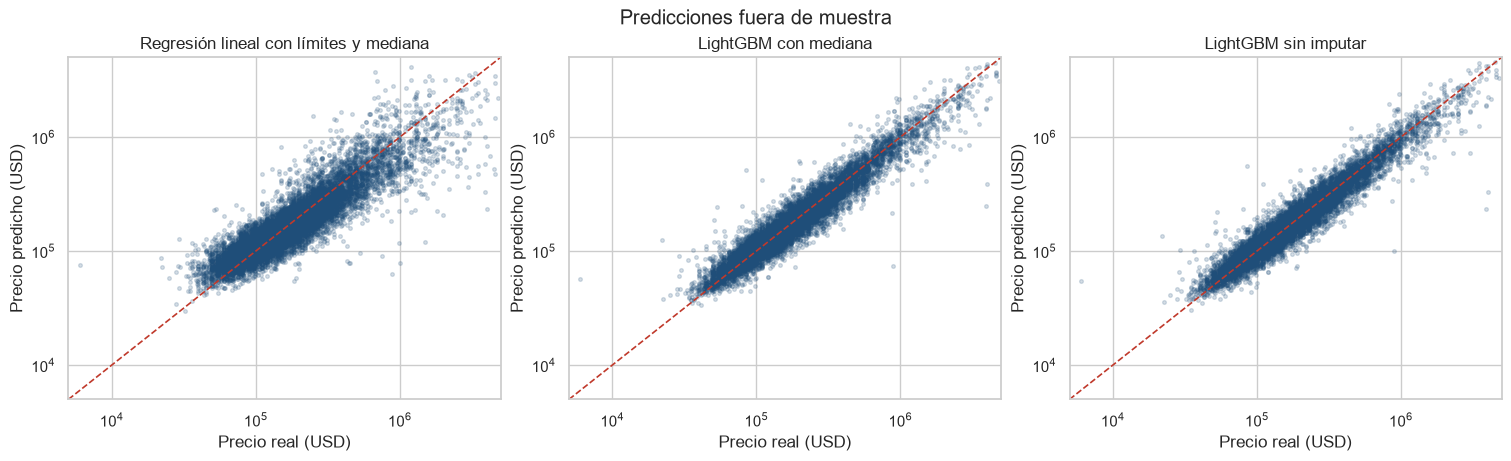

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
limites = [5_000, 5_000_000]

for ax, (nombre, prediccion) in zip(axes, predicciones_test.items()):
    ax.scatter(real_test, prediccion, s=7, alpha=0.18, color="#1f4e79", rasterized=True)
    ax.plot(limites, limites, color="#c0392b", linestyle="--", linewidth=1.2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(limites)
    ax.set_ylim(limites)
    ax.set_title(nombre)
    ax.set_xlabel("Precio real (USD)")
    ax.set_ylabel("Precio predicho (USD)")

fig.suptitle("Predicciones fuera de muestra")
plt.show()

## Importancia de variables con SHAP

Se analiza el LightGBM con menor MAE en test. LightGBM calcula contribuciones TreeSHAP exactas con `pred_contrib=True`; no hace falta aproximarlas ni instalar otra librería. Para mantener el cálculo liviano y reproducible se toma una muestra de hasta 5.000 observaciones del test.

Como el modelo predice `log(precio_usd)`, cada valor SHAP es una contribución al logaritmo del precio. La media del valor absoluto mide importancia global: cuánto mueve una variable la predicción, sin importar la dirección. No mide causalidad.

Modelo explicado: LightGBM sin imputar
Observaciones de test usadas: 5.000
Error máximo de reconstrucción SHAP: 4.09e-14


,feature,media_abs_SHAP_log,participación_%
0,superficie_total,0.3080,28.7
1,barrio,0.2132,19.9
2,antiguedad,0.1030,9.6
3,banos,0.0812,7.6
4,superficie_cubierta,0.0799,7.4
5,cocheras,0.0464,4.3
6,distancia_subte_km,0.0345,3.2
7,pileta,0.0284,2.6
8,toilettes,0.0284,2.6
9,ambientes,0.0277,2.6


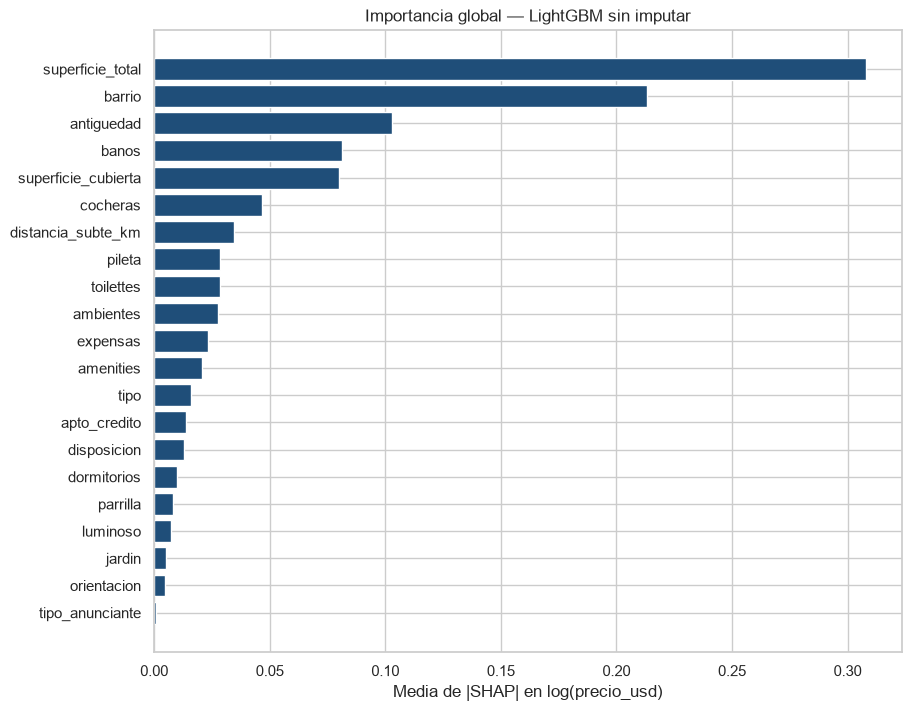

In [9]:
modelos_para_shap = {
    "LightGBM con mediana": (modelo_lgb_imp, X_test_lgb_imp),
    "LightGBM sin imputar": (modelo_lgb_nan, X_test_lgb_nan),
}
ranking_lightgbm = resultados_test[resultados_test["modelo"].isin(modelos_para_shap)].sort_values("MAE_USD")
nombre_modelo_shap = ranking_lightgbm.iloc[0]["modelo"]
modelo_shap, X_test_shap = modelos_para_shap[nombre_modelo_shap]

n_muestra = min(5_000, len(X_test_shap))
X_muestra_shap = X_test_shap.sample(n=n_muestra, random_state=SEED)
contribuciones = modelo_shap.booster_.predict(
    X_muestra_shap,
    num_iteration=modelo_shap.best_iteration_,
    pred_contrib=True,
)
valores_shap = contribuciones[:, :-1]
valor_base = contribuciones[:, -1]

# TreeSHAP debe reconstruir la predicción en escala logarítmica.
pred_log_muestra = modelo_shap.predict(
    X_muestra_shap,
    num_iteration=modelo_shap.best_iteration_,
)
error_reconstruccion = np.max(
    np.abs(pred_log_muestra - (valor_base + valores_shap.sum(axis=1)))
)

importancia_shap = (
    pd.DataFrame(
        {
            "feature": X_muestra_shap.columns,
            "media_abs_SHAP_log": np.abs(valores_shap).mean(axis=0),
        }
    )
    .sort_values("media_abs_SHAP_log", ascending=False)
    .reset_index(drop=True)
)
importancia_shap["participación_%"] = (
    100 * importancia_shap["media_abs_SHAP_log"] / importancia_shap["media_abs_SHAP_log"].sum()
)

print(f"Modelo explicado: {nombre_modelo_shap}")
print(f"Observaciones de test usadas: {n_muestra:,}".replace(",", "."))
print(f"Error máximo de reconstrucción SHAP: {error_reconstruccion:.2e}")
display(importancia_shap.style.format({"media_abs_SHAP_log": "{:.4f}", "participación_%": "{:.1f}"}))

orden_plot = importancia_shap.sort_values("media_abs_SHAP_log")
fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
ax.barh(orden_plot["feature"], orden_plot["media_abs_SHAP_log"], color="#1f4e79")
ax.set_xlabel("Media de |SHAP| en log(precio_usd)")
ax.set_ylabel("")
ax.set_title(f"Importancia global — {nombre_modelo_shap}")
plt.show()